<h1 align=center style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
کنکلی
</font>
</h1>

<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
مقدمه و صورت مسئله
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    در این تمرین قصد داریم پیش‌بینی کنیم آیا کاربران بلیط خود را کنسل می‌کنند یا نه. به ازای هر کنسلی، مستربلیط باید به شرکت مسافربری جریمه پرداخت کند! پس بلیط‌های    کنسلی به معنی تحمیل هزینه به شرکت است. از این رو تشخیص دادن بلیط‌هایی که احتمال کنسلی آنان وجود دارد، به مدیریت ریسک شرکت کمک بزرگی می‌کند.
    <br>
    حال از داده‌هایی که در اختیارتان قرار گرفته است استفاده کنید و مدلی آموزش دهید که کنسل شدن یا نشدن سفر را تشخیص دهد.
</font>
</p>

<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
وارد کردن کتابخانه‌های مورد نیاز
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    ابتدا کتابخانه‌های مورد نیازتان را وارد کنید.
</font>
</p>

In [1]:
import pandas as pd
import numpy as np

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
معرفی مجموعه داده
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
مجموعه داده آموزشی شامل ۱۰۱۰۱۷ سطر است که در جدول زیر، توضیحات هر ستون آمده است.
</font>
</p>

<center>
<div dir=rtl style="direction: rtl;line-height:200%;font-family:vazir;font-size:medium">
<font face="vazir" size=3>
    
|ستون|توضیحات|
|:------:|:---:|
|Created|زمان ثبت بلیط|
|CancelTime|زمانی که مسافر بلیط را کنسل کرده است|
|DepartureTime|زمان حرکت|
|BillID|شناسه خرید|
|TicketID|شناسه بلیط|
|ReserveStatus|وضعیت پرداخت مشتری|
|UserID|شناسه کاربری|
|Male|آیا بلیط متعلق به زن است یا مرد|
|Price|قیمت بلیط بدون تخفیف|
|CouponDiscount|تخفیفی که شخص روی بلیط اعمال کرده است|
|From|مبدا سفر|
|To|مقصد سفر|
|Domestic|آیا سفر، داخلی است یا خارجی|
|VehicleType|جزئیات وسیله نقلیه را مشخص می‌کند|
|VehicleClass|آیا وسیله نقلیه، فرست‌کلس است یا نه|
|Vehicle|نوع وسیله نقلیه|
|HashPassportNumber_p|هش‌شده شماره پاسپورت|
|HashEmail|هش‌شده ایمیل|
|BuyerMobile|هش‌شده شماره موبایل|
|NationalCode|هش‌شده شماره‌ملی|
|TripReason|دلیل سفر|
|Cancel|آیا بلیط کنسل شده‌است یا نه|
    
</font>
</div>
</center>


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    مجموعه داده آزمایش نیز مانند مجموعه آموزش است با این تفاوت که ستون <code>Cancel</code> که متغیر هدف مسئله است را در خود ندارد. مجموعه داده آزمایش ۴۳۲۹۳ سطر دارد.
</font>
</p>


<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
خواندن مجموعه داده
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    در ابتدا نیاز است فایل‌های مجموعه‌داده را بخوانید. نمونه‌های آموزشی در فایل <code>train_data.csv</code> و نمونه‌های آزمون که باید دسته‌ی آن‌ها را پیش‌بینی کنید در فایل <code>test_data.csv</code> ذخیره شده‌اند. اگر لازم دانستید می‌توانید به دلخواه خود بخشی از مجموعه داده آموزشی را به عنوان مجموعه داده اعتبارسنجی نیز جدا کنید.
</font>
</p>

In [3]:
train_data = pd.read_csv('/content/drive/MyDrive/ML/Quera_exercise/کنکلی/train_data.csv')
train_data

,Created,CancelTime,DepartureTime,BillID,TicketID,ReserveStatus,UserID,Male,Price,CouponDiscount,...,Domestic,VehicleType,VehicleClass,TripReason,Vehicle,Cancel,HashPassportNumber_p,HashEmail,BuyerMobile,NationalCode
0,2022-07-26 13:33:20.457,NaN,2022-07-26 16:30:00,38428546,7445571.0,3,NaN,True,1180000.0,0.0,...,1,VIPمانیتوردار-شارژراختصاصی تخت شو مارال (جدید)...,True,Work,Bus,0,NaN,NaN,302222356019,330024570
1,2022-10-27 23:07:01.837,2022-10-27 23:26:39.070,2022-10-29 09:45:00,39768762,7762719.0,5,NaN,False,1050000.0,0.0,...,1,classicus 2+2,True,Int,Bus,1,NaN,NaN,900764168521,995520696
2,2022-09-12 11:01:13.607,NaN,2022-10-03 18:35:00,39128001,2327596.0,5,800398.0,False,4674000.0,0.0,...,1,فوکر 100,False,Int,Plane,0,NaN,1c44d7a76b52341fa12dcfa993138576befcc9ebf01d14...,749804783291,979382950
3,2022-08-08 17:43:35.840,NaN,2022-08-08 22:30:00,38606546,7495440.0,3,NaN,True,1200000.0,0.0,...,1,VIPدرسا+مانیتوردار+شارژراختصاصی+پذیرایی,True,Work,Bus,0,NaN,NaN,781396205677,911237229
4,2022-11-01 15:12:56.823,NaN,2022-11-03 11:30:00,39822185,2356902.0,5,NaN,True,6222000.0,0.0,...,1,NaN,False,Work,Plane,0,NaN,bb38b345aec02255e31d178492907175c5984f2a1f5b59...,524576220177,727496008
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101012,2022-10-27 21:41:35.803,NaN,2022-11-05 20:15:00,39767774,3082282.0,2,NaN,False,7200000.0,0.0,...,1,5ستاره بيزينس سلامت فدك,NaN,Int,Train,0,NaN,NaN,395081863564,789320493
101013,2022-09-24 15:51:11.993,NaN,2022-10-21 09:15:00,39319207,3026516.0,2,151423.0,False,4292000.0,0.0,...,1,4ستاره4تخته سپهر,NaN,Int,Train,0,NaN,3f28ed65a16d629747e4d27fab100b2b082fcbdf7ec831...,130026405332,866503410
101014,2022-08-12 13:46:20.480,NaN,2022-08-12 23:59:00,38653461,7508988.0,3,NaN,True,1320000.0,0.0,...,1,VIP 2+1 / مانیتوردار / سیستم تهویه مطبوع / تخ...,True,Int,Bus,0,NaN,NaN,784949357488,881677039
101015,2022-06-20 15:15:37.780,NaN,2022-06-25 10:10:00,37880627,1057205.0,5,641744.0,True,13000000.0,0.0,...,1,NaN,False,Work,Plane,0,NaN,750690ca99468f159eff6ad928cec4339b089af8c2e6dc...,766602541733,403505466


In [4]:
test_data = pd.read_csv('/content/drive/MyDrive/ML/Quera_exercise/کنکلی/test_data.csv')
test_data

,Created,DepartureTime,BillID,TicketID,ReserveStatus,UserID,Male,Price,CouponDiscount,From,To,Domestic,VehicleType,VehicleClass,TripReason,Vehicle,HashPassportNumber_p,HashEmail,BuyerMobile,NationalCode
0,2022-07-08 12:04:46.290,2022-08-16 23:59:00,38166794,2890395.0,2,NaN,False,2043000.0,0.0,مشهد,تهران,1,3 ستاره 6 تخته پارسي,NaN,Int,Train,NaN,NaN,419509763088,660703096
1,2022-09-30 14:18:23.487,2022-09-30 23:59:00,39424175,7669420.0,3,NaN,False,1220000.0,0.0,تهران,اصفهان,1,V I P,True,Int,Bus,NaN,NaN,935955347521,960594437
2,2022-05-15 10:52:01.293,2022-06-06 17:40:00,37336619,2783057.0,2,800538.0,True,2132000.0,0.0,مشهد,تهران,1,4ستاره 4تخته سبز نوين,NaN,Int,Train,NaN,NaN,428059757595,854730165
3,2022-10-06 02:55:53.723,2022-10-14 19:45:00,39507715,7691289.0,5,950983.0,False,520000.0,0.0,تهران,سمنان,1,اسکانیا,True,Work,Bus,NaN,012dca1b2070c32e03238f49aa8f12a1a9ce580f8b1368...,515601565031,850531769
4,2022-03-12 13:46:40.300,2022-03-12 19:30:00,36422079,6901256.0,3,NaN,True,1180000.0,0.0,ارومیه,کرمانشاه,1,اسکانیا تک صندلی,True,Work,Bus,NaN,NaN,633910237635,893186872
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43288,2022-09-25 15:33:09.793,2022-09-25 20:30:00,39338188,7647177.0,3,NaN,True,2480000.0,0.0,تهران,مشهد (خراسان ),1,وای پی تخت شو ۲۵نفره,True,Int,Bus,NaN,7091c8c24f3f57b98561de5d9a874cb91c3fd44371930a...,45595252975,158174797
43289,2022-07-16 19:58:15.300,2022-07-18 21:45:00,38298325,7406150.0,3,NaN,True,1330000.0,0.0,اصفهان,شیراز,1,اسکانیا درسا(مانیتور اختصاصی),True,Work,Bus,NaN,NaN,194871920550,384954737
43290,2022-06-16 18:14:40.673,2022-06-17 17:30:00,37823306,7274287.0,3,NaN,True,1290000.0,0.0,تهران,رودسر,1,مارال 25 نفره VIP,True,Int,Bus,NaN,NaN,687841588584,648554818
43291,2022-07-23 13:48:45.330,2022-08-23 21:05:00,38386540,2914007.0,2,724274.0,True,2810500.0,0.0,مشهد,تهران,1,4 ستاره 4 تخته غزال,NaN,Int,Train,NaN,a78e5ce63b34517a2c4e1d3ccd474241abe1993b49905c...,976918931561,779144272


In [5]:
train_data.describe()

,BillID,TicketID,ReserveStatus,UserID,Price,CouponDiscount,Domestic,Cancel,BuyerMobile,NationalCode
count,1.010170e+05,1.010170e+05,101017.000000,42502.000000,1.010170e+05,1.010170e+05,101017.000000,101017.000000,1.010170e+05,1.010170e+05
mean,3.832697e+07,4.933657e+06,3.163012,578599.685050,3.209691e+06,4.975680e+03,0.992100,0.151470,5.036391e+11,1.429602e+14
std,1.098834e+06,2.411914e+06,1.077199,273695.615099,6.985928e+06,7.074863e+04,0.088529,0.358508,2.877734e+11,9.691330e+15
min,3.591084e+07,1.015844e+06,2.000000,7958.000000,-1.514000e+06,0.000000e+00,0.000000,0.000000,1.170136e+07,2.900000e+02
25%,3.743849e+07,2.848014e+06,2.000000,338280.000000,1.080000e+06,0.000000e+00,1.000000,0.000000,2.573053e+11,2.505874e+08
50%,3.855474e+07,3.078420e+06,3.000000,614987.000000,1.690000e+06,0.000000e+00,1.000000,0.000000,5.049426e+11,5.020345e+08
75%,3.931181e+07,7.431083e+06,4.000000,822011.250000,3.067000e+06,0.000000e+00,1.000000,0.000000,7.508900e+11,7.503344e+08
max,3.984016e+07,7.782861e+06,5.000000,983332.000000,3.837646e+08,1.443333e+07,1.000000,1.000000,9.999831e+11,9.790847e+17


In [6]:
test_data.describe()

,BillID,TicketID,ReserveStatus,UserID,Price,CouponDiscount,Domestic,BuyerMobile,NationalCode
count,4.329300e+04,4.329300e+04,43293.000000,18345.000000,4.329300e+04,4.329300e+04,43293.000000,4.329300e+04,4.329300e+04
mean,3.832549e+07,4.945472e+06,3.158155,579240.128100,3.275940e+06,4.462558e+03,0.991731,5.037615e+11,1.602953e+14
std,1.099557e+06,2.409068e+06,1.071651,272172.665728,8.386017e+06,3.819232e+04,0.090560,2.883079e+11,1.065095e+16
min,3.581478e+07,1.015932e+06,2.000000,7958.000000,3.250000e+04,-2.000000e+03,0.000000,2.372505e+07,2.900000e+02
25%,3.743360e+07,2.854478e+06,2.000000,342411.000000,1.074000e+06,0.000000e+00,1.000000,2.568322e+11,2.499016e+08
50%,3.855418e+07,3.080410e+06,3.000000,614427.000000,1.690000e+06,0.000000e+00,1.000000,5.048971e+11,5.019751e+08
75%,3.930865e+07,7.433011e+06,4.000000,820519.000000,3.031000e+06,0.000000e+00,1.000000,7.538832e+11,7.524986e+08
max,3.984015e+07,7.782877e+06,5.000000,983278.000000,3.837646e+08,2.000000e+06,1.000000,9.999843e+11,9.986287e+17


In [7]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101017 entries, 0 to 101016
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Created               101017 non-null  object 
 1   CancelTime            15312 non-null   object 
 2   DepartureTime         101017 non-null  object 
 3   BillID                101017 non-null  int64  
 4   TicketID              101017 non-null  float64
 5   ReserveStatus         101017 non-null  int64  
 6   UserID                42502 non-null   float64
 7   Male                  101017 non-null  bool   
 8   Price                 101017 non-null  float64
 9   CouponDiscount        101017 non-null  float64
 10  From                  101017 non-null  object 
 11  To                    101017 non-null  object 
 12  Domestic              101017 non-null  int64  
 13  VehicleType           93339 non-null   object 
 14  VehicleClass          62666 non-null   object 
 15  

In [8]:
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43293 entries, 0 to 43292
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Created               43293 non-null  object 
 1   DepartureTime         43293 non-null  object 
 2   BillID                43293 non-null  int64  
 3   TicketID              43293 non-null  float64
 4   ReserveStatus         43293 non-null  int64  
 5   UserID                18345 non-null  float64
 6   Male                  43293 non-null  bool   
 7   Price                 43293 non-null  float64
 8   CouponDiscount        43293 non-null  float64
 9   From                  43293 non-null  object 
 10  To                    43293 non-null  object 
 11  Domestic              43293 non-null  int64  
 12  VehicleType           40050 non-null  object 
 13  VehicleClass          26856 non-null  object 
 14  TripReason            43293 non-null  object 
 15  Vehicle            

In [9]:
train_data.isnull().sum()

,0
Created,0
CancelTime,85705
DepartureTime,0
BillID,0
TicketID,0
ReserveStatus,0
UserID,58515
Male,0
Price,0
CouponDiscount,0


In [10]:
test_data.isnull().sum()

,0
Created,0
DepartureTime,0
BillID,0
TicketID,0
ReserveStatus,0
UserID,24948
Male,0
Price,0
CouponDiscount,0
From,0


In [11]:
train_data.isin(['?']).sum(axis=0)

,0
Created,0
CancelTime,0
DepartureTime,0
BillID,0
TicketID,0
ReserveStatus,0
UserID,0
Male,0
Price,0
CouponDiscount,0


In [12]:
test_data.isin(['?']).sum(axis=0)

,0
Created,0
DepartureTime,0
BillID,0
TicketID,0
ReserveStatus,0
UserID,0
Male,0
Price,0
CouponDiscount,0
From,0


In [13]:
train_data['Cancel'].value_counts()

,count
Cancel,
0,85716
1,15301


(array([85716.,     0.,     0.,     0.,     0.,     0.,     0.,     0.,
            0., 15301.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

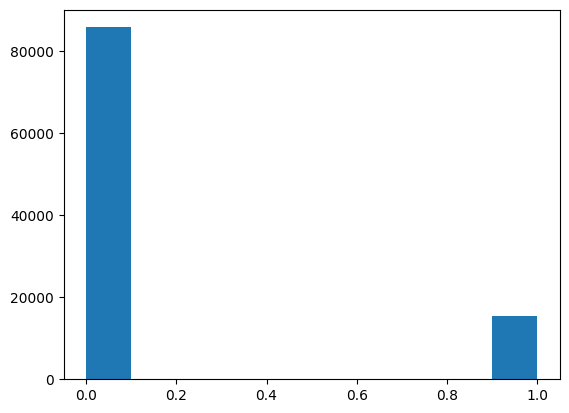

In [14]:
import matplotlib.pyplot as plt
plt.hist(train_data['Cancel'])

<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
پیش‌پردازش و مهندسی ویژگی
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    در این سوال شما می‌توانید از هر تکنیک پیش‌پردازش/مهندسی ویژگی که در فصل‌های گذشته آموختید، استفاده کنید.
    <br>
    تکنیک‌هایی که استفاده می‌کنید به شکل مستقیم مورد ارزیابی توسط سامانه داوری قرار <b>نمی‌گیرند.</b> بلکه همه آن‌ها در دقت مدل شما تاثیر خواهند گذاشت؛ بنابراین هر چه پیش‌پردازش/مهندسی ویژگی بهتری انجام دهید تا دقت مدل بهبود پیدا کند، امتیاز بیشتری از این سوال کسب خواهید کرد.
</font>
</p>

In [15]:
# Drop columns
train_data = train_data.drop(['CancelTime', 'HashPassportNumber_p', 'HashEmail', 'BuyerMobile', 'NationalCode', 'BillID', 'TicketID', 'Vehicle', 'UserID'], axis=1)
train_data

,Created,DepartureTime,ReserveStatus,Male,Price,CouponDiscount,From,To,Domestic,VehicleType,VehicleClass,TripReason,Cancel
0,2022-07-26 13:33:20.457,2022-07-26 16:30:00,3,True,1180000.0,0.0,شیراز,سیرجان,1,VIPمانیتوردار-شارژراختصاصی تخت شو مارال (جدید)...,True,Work,0
1,2022-10-27 23:07:01.837,2022-10-29 09:45:00,5,False,1050000.0,0.0,قم,ساری,1,classicus 2+2,True,Int,1
2,2022-09-12 11:01:13.607,2022-10-03 18:35:00,5,False,4674000.0,0.0,تهران,ارومیه,1,فوکر 100,False,Int,0
3,2022-08-08 17:43:35.840,2022-08-08 22:30:00,3,True,1200000.0,0.0,تهران,ملایر,1,VIPدرسا+مانیتوردار+شارژراختصاصی+پذیرایی,True,Work,0
4,2022-11-01 15:12:56.823,2022-11-03 11:30:00,5,True,6222000.0,0.0,چابهار,تهران,1,NaN,False,Work,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
101012,2022-10-27 21:41:35.803,2022-11-05 20:15:00,2,False,7200000.0,0.0,مشهد,تهران,1,5ستاره بيزينس سلامت فدك,NaN,Int,0
101013,2022-09-24 15:51:11.993,2022-10-21 09:15:00,2,False,4292000.0,0.0,مشهد,اصفهان,1,4ستاره4تخته سپهر,NaN,Int,0
101014,2022-08-12 13:46:20.480,2022-08-12 23:59:00,3,True,1320000.0,0.0,شیراز,اصفهان,1,VIP 2+1 / مانیتوردار / سیستم تهویه مطبوع / تخ...,True,Int,0
101015,2022-06-20 15:15:37.780,2022-06-25 10:10:00,5,True,13000000.0,0.0,تهران,زاهدان,1,NaN,False,Work,0


In [16]:
# Drop columns
test_data = test_data.drop(['HashPassportNumber_p', 'HashEmail', 'BuyerMobile', 'NationalCode', 'BillID', 'TicketID', 'Vehicle', 'UserID'], axis=1)
test_data

,Created,DepartureTime,ReserveStatus,Male,Price,CouponDiscount,From,To,Domestic,VehicleType,VehicleClass,TripReason
0,2022-07-08 12:04:46.290,2022-08-16 23:59:00,2,False,2043000.0,0.0,مشهد,تهران,1,3 ستاره 6 تخته پارسي,NaN,Int
1,2022-09-30 14:18:23.487,2022-09-30 23:59:00,3,False,1220000.0,0.0,تهران,اصفهان,1,V I P,True,Int
2,2022-05-15 10:52:01.293,2022-06-06 17:40:00,2,True,2132000.0,0.0,مشهد,تهران,1,4ستاره 4تخته سبز نوين,NaN,Int
3,2022-10-06 02:55:53.723,2022-10-14 19:45:00,5,False,520000.0,0.0,تهران,سمنان,1,اسکانیا,True,Work
4,2022-03-12 13:46:40.300,2022-03-12 19:30:00,3,True,1180000.0,0.0,ارومیه,کرمانشاه,1,اسکانیا تک صندلی,True,Work
...,...,...,...,...,...,...,...,...,...,...,...,...
43288,2022-09-25 15:33:09.793,2022-09-25 20:30:00,3,True,2480000.0,0.0,تهران,مشهد (خراسان ),1,وای پی تخت شو ۲۵نفره,True,Int
43289,2022-07-16 19:58:15.300,2022-07-18 21:45:00,3,True,1330000.0,0.0,اصفهان,شیراز,1,اسکانیا درسا(مانیتور اختصاصی),True,Work
43290,2022-06-16 18:14:40.673,2022-06-17 17:30:00,3,True,1290000.0,0.0,تهران,رودسر,1,مارال 25 نفره VIP,True,Int
43291,2022-07-23 13:48:45.330,2022-08-23 21:05:00,2,True,2810500.0,0.0,مشهد,تهران,1,4 ستاره 4 تخته غزال,NaN,Int


In [17]:
train_data.isnull().sum()

,0
Created,0
DepartureTime,0
ReserveStatus,0
Male,0
Price,0
CouponDiscount,0
From,0
To,0
Domestic,0
VehicleType,7678


In [18]:
test_data.isnull().sum()

,0
Created,0
DepartureTime,0
ReserveStatus,0
Male,0
Price,0
CouponDiscount,0
From,0
To,0
Domestic,0
VehicleType,3243


Impute Missing Values

In [19]:
train_data['VehicleType'] = train_data['VehicleType'].fillna(train_data['VehicleType'].mode()[0])
train_data['VehicleClass'] = train_data['VehicleClass'].fillna(train_data['VehicleClass'].mode()[0])

/tmp/ipykernel_952/526505651.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_data['VehicleClass'] = train_data['VehicleClass'].fillna(train_data['VehicleClass'].mode()[0])


In [20]:
test_data['VehicleType'] = test_data['VehicleType'].fillna(test_data['VehicleType'].mode()[0])
test_data['VehicleClass'] = test_data['VehicleClass'].fillna(test_data['VehicleClass'].mode()[0])

/tmp/ipykernel_952/668239504.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test_data['VehicleClass'] = test_data['VehicleClass'].fillna(test_data['VehicleClass'].mode()[0])


In [21]:
train_data.isnull().sum()

,0
Created,0
DepartureTime,0
ReserveStatus,0
Male,0
Price,0
CouponDiscount,0
From,0
To,0
Domestic,0
VehicleType,0


In [22]:
test_data.isnull().sum()

,0
Created,0
DepartureTime,0
ReserveStatus,0
Male,0
Price,0
CouponDiscount,0
From,0
To,0
Domestic,0
VehicleType,0


feature extraction

In [23]:
train_data['Created'] = pd.to_datetime(train_data['Created'])
train_data['DepartureTime'] = pd.to_datetime(train_data['DepartureTime'])
test_data['Created'] = pd.to_datetime(test_data['Created'])
test_data['DepartureTime'] = pd.to_datetime(test_data['DepartureTime'])

train_data['Created_year'] = train_data['Created'].dt.year
train_data['Created_month'] = train_data['Created'].dt.month
train_data['Created_day'] = train_data['Created'].dt.day
train_data['Created_hour'] = train_data['Created'].dt.hour
train_data['Created_minute'] = train_data['Created'].dt.minute
train_data['Created_weekday'] = train_data['Created'].dt.weekday

test_data['Created_year'] = test_data['Created'].dt.year
test_data['Created_month'] = test_data['Created'].dt.month
test_data['Created_day'] = test_data['Created'].dt.day
test_data['Created_hour'] = test_data['Created'].dt.hour
test_data['Created_minute'] = test_data['Created'].dt.minute
test_data['Created_weekday'] = test_data['Created'].dt.weekday


train_data['Departure_year'] = train_data['DepartureTime'].dt.year
train_data['Departure_month'] = train_data['DepartureTime'].dt.month
train_data['Departure_day'] = train_data['DepartureTime'].dt.day
train_data['Departure_hour'] = train_data['DepartureTime'].dt.hour
train_data['Departure_minute'] = train_data['DepartureTime'].dt.minute
train_data['Departure_weekday'] = train_data['DepartureTime'].dt.weekday

test_data['Departure_year'] = test_data['DepartureTime'].dt.year
test_data['Departure_month'] = test_data['DepartureTime'].dt.month
test_data['Departure_day'] = test_data['DepartureTime'].dt.day
test_data['Departure_hour'] = test_data['DepartureTime'].dt.hour
test_data['Departure_minute'] = test_data['DepartureTime'].dt.minute
test_data['Departure_weekday'] = test_data['DepartureTime'].dt.weekday

train_data.drop(['Created', 'DepartureTime'], axis=1, inplace=True)
test_data.drop(['Created', 'DepartureTime'], axis=1, inplace=True)

In [24]:
train_data

,ReserveStatus,Male,Price,CouponDiscount,From,To,Domestic,VehicleType,VehicleClass,TripReason,...,Created_day,Created_hour,Created_minute,Created_weekday,Departure_year,Departure_month,Departure_day,Departure_hour,Departure_minute,Departure_weekday
0,3,True,1180000.0,0.0,شیراز,سیرجان,1,VIPمانیتوردار-شارژراختصاصی تخت شو مارال (جدید)...,True,Work,...,26,13,33,1,2022,7,26,16,30,1
1,5,False,1050000.0,0.0,قم,ساری,1,classicus 2+2,True,Int,...,27,23,7,3,2022,10,29,9,45,5
2,5,False,4674000.0,0.0,تهران,ارومیه,1,فوکر 100,False,Int,...,12,11,1,0,2022,10,3,18,35,0
3,3,True,1200000.0,0.0,تهران,ملایر,1,VIPدرسا+مانیتوردار+شارژراختصاصی+پذیرایی,True,Work,...,8,17,43,0,2022,8,8,22,30,0
4,5,True,6222000.0,0.0,چابهار,تهران,1,4 ستاره اتوبوسي صبا,False,Work,...,1,15,12,1,2022,11,3,11,30,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101012,2,False,7200000.0,0.0,مشهد,تهران,1,5ستاره بيزينس سلامت فدك,True,Int,...,27,21,41,3,2022,11,5,20,15,5
101013,2,False,4292000.0,0.0,مشهد,اصفهان,1,4ستاره4تخته سپهر,True,Int,...,24,15,51,5,2022,10,21,9,15,4
101014,3,True,1320000.0,0.0,شیراز,اصفهان,1,VIP 2+1 / مانیتوردار / سیستم تهویه مطبوع / تخ...,True,Int,...,12,13,46,4,2022,8,12,23,59,4
101015,5,True,13000000.0,0.0,تهران,زاهدان,1,4 ستاره اتوبوسي صبا,False,Work,...,20,15,15,0,2022,6,25,10,10,5


In [25]:
test_data

,ReserveStatus,Male,Price,CouponDiscount,From,To,Domestic,VehicleType,VehicleClass,TripReason,...,Created_day,Created_hour,Created_minute,Created_weekday,Departure_year,Departure_month,Departure_day,Departure_hour,Departure_minute,Departure_weekday
0,2,False,2043000.0,0.0,مشهد,تهران,1,3 ستاره 6 تخته پارسي,True,Int,...,8,12,4,4,2022,8,16,23,59,1
1,3,False,1220000.0,0.0,تهران,اصفهان,1,V I P,True,Int,...,30,14,18,4,2022,9,30,23,59,4
2,2,True,2132000.0,0.0,مشهد,تهران,1,4ستاره 4تخته سبز نوين,True,Int,...,15,10,52,6,2022,6,6,17,40,0
3,5,False,520000.0,0.0,تهران,سمنان,1,اسکانیا,True,Work,...,6,2,55,3,2022,10,14,19,45,4
4,3,True,1180000.0,0.0,ارومیه,کرمانشاه,1,اسکانیا تک صندلی,True,Work,...,12,13,46,5,2022,3,12,19,30,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43288,3,True,2480000.0,0.0,تهران,مشهد (خراسان ),1,وای پی تخت شو ۲۵نفره,True,Int,...,25,15,33,6,2022,9,25,20,30,6
43289,3,True,1330000.0,0.0,اصفهان,شیراز,1,اسکانیا درسا(مانیتور اختصاصی),True,Work,...,16,19,58,5,2022,7,18,21,45,0
43290,3,True,1290000.0,0.0,تهران,رودسر,1,مارال 25 نفره VIP,True,Int,...,16,18,14,3,2022,6,17,17,30,4
43291,2,True,2810500.0,0.0,مشهد,تهران,1,4 ستاره 4 تخته غزال,True,Int,...,23,13,48,5,2022,8,23,21,5,1


train test split

In [26]:
from sklearn.model_selection import train_test_split

X = train_data.drop('Cancel', axis=1)
y = train_data['Cancel']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=1)


In [27]:
from sklearn.preprocessing import OrdinalEncoder

categorical_columns = X_train.select_dtypes(include=['object']).columns.tolist()

for col in categorical_columns:

  # Apply OrdinalEncoder with handle_unknown='use_encoded_value'
  ordinal_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

  # Transform both training and test data
  X_train[col] = ordinal_encoder.fit_transform(X_train[[col]])
  X_val[col] = ordinal_encoder.transform(X_val[[col]])
  test_data[col] = ordinal_encoder.transform(test_data[[col]])


In [28]:
X_train.head()

,ReserveStatus,Male,Price,CouponDiscount,From,To,Domestic,VehicleType,VehicleClass,TripReason,...,Created_day,Created_hour,Created_minute,Created_weekday,Departure_year,Departure_month,Departure_day,Departure_hour,Departure_minute,Departure_weekday
41074,2,False,1553000.0,0.0,162.0,73.0,1,120.0,True,1.0,...,23,22,36,0,2022,5,27,7,40,4
29276,5,True,950000.0,0.0,62.0,92.0,1,1148.0,True,0.0,...,2,11,36,3,2022,6,2,20,0,3
24450,2,False,976500.0,0.0,62.0,150.0,1,109.0,True,0.0,...,12,6,13,2,2022,10,13,13,30,3
97198,3,True,2080000.0,0.0,163.0,40.0,1,682.0,True,1.0,...,30,19,4,4,2022,10,1,19,30,5
6518,2,False,3237000.0,7500.0,128.0,210.0,1,143.0,True,0.0,...,25,12,55,0,2022,5,1,16,0,6


In [29]:
X_val.head()

,ReserveStatus,Male,Price,CouponDiscount,From,To,Domestic,VehicleType,VehicleClass,TripReason,...,Created_day,Created_hour,Created_minute,Created_weekday,Departure_year,Departure_month,Departure_day,Departure_hour,Departure_minute,Departure_weekday
59717,5,False,10191000.0,0.0,162.0,73.0,1,1575.0,False,1.0,...,22,22,59,5,2022,10,24,11,0,0
13220,3,True,930000.0,0.0,185.0,188.0,1,1484.0,True,1.0,...,20,17,41,5,2022,8,21,9,30,6
94291,3,True,1690000.0,0.0,62.0,67.0,1,1003.0,True,1.0,...,8,20,26,6,2022,5,8,23,0,6
82961,2,False,3407500.0,0.0,162.0,73.0,1,135.0,True,0.0,...,29,9,19,3,2022,10,20,18,5,3
98578,2,True,426500.0,0.0,111.0,73.0,1,120.0,True,1.0,...,7,9,51,2,2022,9,21,16,40,2


In [30]:
test_data.head()

,ReserveStatus,Male,Price,CouponDiscount,From,To,Domestic,VehicleType,VehicleClass,TripReason,...,Created_day,Created_hour,Created_minute,Created_weekday,Departure_year,Departure_month,Departure_day,Departure_hour,Departure_minute,Departure_weekday
0,2,False,2043000.0,0.0,162.0,73.0,1,89.0,True,0.0,...,8,12,4,4,2022,8,16,23,59,1
1,3,False,1220000.0,0.0,62.0,27.0,1,633.0,True,0.0,...,30,14,18,4,2022,9,30,23,59,4
2,2,True,2132000.0,0.0,162.0,73.0,1,141.0,True,0.0,...,15,10,52,6,2022,6,6,17,40,0
3,5,False,520000.0,0.0,62.0,143.0,1,1178.0,True,1.0,...,6,2,55,3,2022,10,14,19,45,4
4,3,True,1180000.0,0.0,17.0,265.0,1,1243.0,True,1.0,...,12,13,46,5,2022,3,12,19,30,5


In [31]:
train_data['Cancel'].head()

,Cancel
0,0
1,1
2,0
3,0
4,0


In [32]:
bool_columns = [col for col in X_train.columns if len(X_train[col].unique()) <=2]
X_train[bool_columns]

,Male,Domestic,VehicleClass,TripReason,Created_year,Departure_year
41074,False,1,True,1.0,2022,2022
29276,True,1,True,0.0,2022,2022
24450,False,1,True,0.0,2022,2022
97198,True,1,True,1.0,2022,2022
6518,False,1,True,0.0,2022,2022
...,...,...,...,...,...,...
50057,False,1,True,1.0,2022,2022
98047,True,1,True,1.0,2022,2022
5192,True,1,False,1.0,2022,2022
77708,False,1,True,1.0,2022,2022


In [33]:
# Identify boolean columns and convert them to integers
boolean_columns = X_train.select_dtypes(include='bool').columns

for col in boolean_columns:
  X_train[col] = X_train[col].astype(int)
  X_val[col] = X_val[col].astype(int)
  test_data[col] = test_data[col].astype(int)

In [34]:
X_train.head()

,ReserveStatus,Male,Price,CouponDiscount,From,To,Domestic,VehicleType,VehicleClass,TripReason,...,Created_day,Created_hour,Created_minute,Created_weekday,Departure_year,Departure_month,Departure_day,Departure_hour,Departure_minute,Departure_weekday
41074,2,0,1553000.0,0.0,162.0,73.0,1,120.0,1,1.0,...,23,22,36,0,2022,5,27,7,40,4
29276,5,1,950000.0,0.0,62.0,92.0,1,1148.0,1,0.0,...,2,11,36,3,2022,6,2,20,0,3
24450,2,0,976500.0,0.0,62.0,150.0,1,109.0,1,0.0,...,12,6,13,2,2022,10,13,13,30,3
97198,3,1,2080000.0,0.0,163.0,40.0,1,682.0,1,1.0,...,30,19,4,4,2022,10,1,19,30,5
6518,2,0,3237000.0,7500.0,128.0,210.0,1,143.0,1,0.0,...,25,12,55,0,2022,5,1,16,0,6


In [35]:
X_val.head()

,ReserveStatus,Male,Price,CouponDiscount,From,To,Domestic,VehicleType,VehicleClass,TripReason,...,Created_day,Created_hour,Created_minute,Created_weekday,Departure_year,Departure_month,Departure_day,Departure_hour,Departure_minute,Departure_weekday
59717,5,0,10191000.0,0.0,162.0,73.0,1,1575.0,0,1.0,...,22,22,59,5,2022,10,24,11,0,0
13220,3,1,930000.0,0.0,185.0,188.0,1,1484.0,1,1.0,...,20,17,41,5,2022,8,21,9,30,6
94291,3,1,1690000.0,0.0,62.0,67.0,1,1003.0,1,1.0,...,8,20,26,6,2022,5,8,23,0,6
82961,2,0,3407500.0,0.0,162.0,73.0,1,135.0,1,0.0,...,29,9,19,3,2022,10,20,18,5,3
98578,2,1,426500.0,0.0,111.0,73.0,1,120.0,1,1.0,...,7,9,51,2,2022,9,21,16,40,2


In [36]:
test_data.head()

,ReserveStatus,Male,Price,CouponDiscount,From,To,Domestic,VehicleType,VehicleClass,TripReason,...,Created_day,Created_hour,Created_minute,Created_weekday,Departure_year,Departure_month,Departure_day,Departure_hour,Departure_minute,Departure_weekday
0,2,0,2043000.0,0.0,162.0,73.0,1,89.0,1,0.0,...,8,12,4,4,2022,8,16,23,59,1
1,3,0,1220000.0,0.0,62.0,27.0,1,633.0,1,0.0,...,30,14,18,4,2022,9,30,23,59,4
2,2,1,2132000.0,0.0,162.0,73.0,1,141.0,1,0.0,...,15,10,52,6,2022,6,6,17,40,0
3,5,0,520000.0,0.0,62.0,143.0,1,1178.0,1,1.0,...,6,2,55,3,2022,10,14,19,45,4
4,3,1,1180000.0,0.0,17.0,265.0,1,1243.0,1,1.0,...,12,13,46,5,2022,3,12,19,30,5


In [37]:
from imblearn.over_sampling import SMOTE



smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

In [38]:
y_resampled.value_counts()

,count
Cancel,
0,64303
1,64303


<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
مدل‌سازی
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    حال که داده را پاکسازی کرده و احتمالا ویژگی‌هایی را به آن افزوده یا از آن حذف کرده‌اید، وقت آن است که مدلی آموزش دهید که بتواند متغیر هدف این مسئله را پیش‌بینی کند.
    <br>
    بر خلاف سایر تمرین‌های کالج، در این تمرین شما مجاز هستید از هر مدلی که آموخته‌اید استفاده کنید. به عبارت بهتر، هدف این سوال پیش‌بینی هرچه بهتر متغیر هدف مسئله است. انتظار ما این است که نحوه کار با کتابخانه‌های یادگیری ماشین را در حدی آموخته باشید که بتوانید با بهترین عملکرد، مسئله را حل کنید!
</font>
</p>

In [40]:
from xgboost import XGBClassifier

# create model instance
bst = XGBClassifier(n_estimators=2, max_depth=2, learning_rate=1, objective='binary:logistic')
# fit model
bst.fit(X_resampled, y_resampled)
# make predictions
y_pred = bst.predict(X_val)

y_pred


array([0, 0, 0, ..., 0, 0, 0])

<h3 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
معیار ارزیابی
</font>
</h3>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    معیاری که برای ارزیابی عملکرد مدل انتخاب کرده‌ایم، <code>f1_score</code> نام دارد.
    <br>
    این معیار، سنجه ارزیابی کیفیت مدل شماست. به عبارت بهتر در سامانه داوری هم از همین معیار برای نمره‌دهی استفاده شده است.
    <br>
    پیشنهاد می‌شود با توجه به این معیار، عملکرد مدل خود را بر روی مجموعه داده آموزش یا اعتبارسنجی ارزیابی کنید.
</font>
</p>

In [41]:
# evaluate model
from sklearn.metrics import  f1_score, classification_report, confusion_matrix

f = f1_score(y_val, y_pred, average='weighted')
f * 100

97.75645305838283

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font color="red"><b color='red'>توجه:</b></font>
<font face="vazir" size=3>
 جهت کسب امتیاز کامل نیاز است تا پاسخ شما حداقل امتیاز <code>95%</code> را با توجه به معیار معرفی‌شده کسب نماید.
</font>
</p>

<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
 پیش‌بینی برای داده تست و خروجی
</font>
</h2>

<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:vazir;font-size:medium">
<font face="vazir" size=3>
    پس از مهندسی ویژگی و مدلسازی، الگوریتمی دارید که می‌تواند شما را از متغیرهای مستقل به متغیر هدف برساند.
    <br>
    از این مدل برای پیش‌بینی نمونه‌های موجود در داده تست استفاده کنید و نتایج را در قالب جدول (<code>dataframe</code>) زیر آماده کنید.
</font>
</p>

<div dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:vazir;font-size:medium">
<font face="vazir" size=3>
    
|ستون|توضیحات|
|------|---|
|Cancel|آیا بلیط کنسل می‌شود یا نه|
    
</font>
</div>



<p dir=rtl style="direction: rtl;text-align: right;line-height:200%;font-family:vazir;font-size:medium">
<font face="vazir" size=3>
    اسم دیتافریم باید <code>submission</code> باشد؛ در غیر این صورت، سامانه داوری نمی‌تواند تلاش‌ شما را ارزیابی کند.
    <br>
    این دیتافریم تنها شامل ۱ ستون با اسم <i>Cancel</i> است و ۴۳۲۹۳ سطر دارد.
    <br>
    به ازای هر سطر موجود در دیتافریم <i>test</i> شما باید یک مقدار پیشبینی شده داشته باشید.
    <br>
    جدول زیر، ۵ سطر ابتدایی دیتافریم <code>submission</code> را نشان می‌دهد. البته در جواب شما، مقادیر ستون <i>Cancel</i> ممکن است متفاوت باشد.
</font>
</p>

<div style="text-align: right;line-height:200%;font-family:vazir;font-size:medium">
<font face="vazir" size=3>
    
||Cancel|
|----|-----|
|0|0|
|1|0|
|2|1|
|3|1|
|4|0|

</font>
</div>



In [42]:
from xgboost import XGBClassifier

# create model instance
bst = XGBClassifier(n_estimators=2, max_depth=2, learning_rate=1, objective='binary:logistic')
# fit model
bst.fit(X_resampled, y_resampled)
# make predictions
y_pred = bst.predict(test_data)


In [43]:
# predict test samples
submission = pd.DataFrame(y_pred, columns = ['Cancel'])
submission

,Cancel
0,0
1,0
2,0
3,1
4,0
...,...
43288,0
43289,0
43290,0
43291,0


<h2 align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
<b>سلول جواب‌ساز</b>
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
    برای ساخته‌شدن فایل <code>result.zip</code> سلول زیر را اجرا کنید. توجه داشته باشید که پیش از اجرای سلول زیر تغییرات اعمال شده در نت‌بوک را ذخیره کرده باشید (<code>ctrl+s</code>) تا در صورت نیاز به پشتیبانی امکان بررسی کد شما وجود داشته باشد.
</font>
</p>

In [ ]:
import zipfile
import joblib

def compress(file_names):
    print("File Paths:")
    print(file_names)
    compression = zipfile.ZIP_DEFLATED
    with zipfile.ZipFile("result.zip", mode="w") as zf:
        for file_name in file_names:
            zf.write('./' + file_name, file_name, compress_type=compression)

submission.to_csv('submission.csv', index=False)
file_names = ['canceli.ipynb', 'submission.csv']
compress(file_names)